# Проект. Исследование стартапов
- Автор: Повшедная Наталья
- Дата: 07.07.2026

## <a id='bullet_1'></a>  Введение

<a id='bullet_16'></a> Содержимое проекта

- [1. Введение](#bullet_1)
    - [1.2 Загрузка данных и знакомство с ними](#bullet_2)
    - [1.3 Предобработка данных](#bullet_3)
- [2. Инжиниринг признаков](#bullet_4)
    - [2.1 Группы по срокам финансирования](#bullet_5)
    - [2.2 Выделение средних и нишевых сегментов рынка](#bullet_6)
- [3. Работа с выбросами и анализ](#bullet_7)
    - [3.1 Анализируем и помечаем выбросы в каждом из сегментов](#bullet_8)
    - [3.2 Определяем границы рассматриваемого периода, отбрасываем аномалии](#bullet_9)
    - [3.3 Анализ типов финансирования по объёму и популярности](#bullet_10)
- [4. Анализ динамики](#bullet_11)
    - [4.1 Динамика предоставления финансирования по годам](#bullet_12)
    - [4.2 Динамика размера общего финансирования по массовым сегментам рынка для растущих в 2014 году сегментов](#bullet_13)
    - [4.3 Годовая динамика доли возвращённых средств по типам финансирования](#bullet_14)
- [5. Итоговый вывод и рекомендации](#bullet_15)

### Цели и задачи проекта
Цель проекта:
- Провести исследовательский анализ данных о финансировании стартапов, выявить закономерности привлечения инвестиций, оценить динамику развития рынка и на основе полученных результатов сформулировать рекомендации по выбору наиболее перспективных направлений для венчурного инвестирования по состоянию на 2015 год.

Задачи проекта
- выполнить предобработку данных: обработать пропуски, удалить дубликаты, проверить корректность числовых и временных данных;
- проанализировать сроки финансирования компаний и разделить их на группы;
- классифицировать сегменты рынка на массовые, средние и нишевые;
- исследовать распределение объёмов финансирования, выявить и исключить аномальные значения;
- сравнить популярность различных типов финансирования и объёмы привлечённых инвестиций;
- проанализировать динамику инвестиционных раундов и объёмов финансирования по годам;
- рассчитать долю возврата средств для различных типов финансирования и оценить её устойчивость;
- сформулировать выводы и рекомендации для инвесторов по наиболее перспективным стратегиям вложения средств.


###  <a id='bullet_2'></a> Знакомство с данными: загрузка и предобработка

Датасет получен из базы данных стартапов.

Название основного датасета — `cb_investments.zip`. Внутри архива один файл — `cb_investments.csv`.

Описание данных:
* `name` — название компании.
* `homepage_url` — ссылка на сайт компании.
* `category_list` — категории, в которых работает компания. Указываются через `|`.
* `market` — основной рынок или отрасль компании.
* `funding_total_usd` — общий объём привлечённых инвестиций в долларах США.
* `status` — текущий статус компании, например `operating`, `closed` и так далее.
* `country_code` — код страны, например USA.
* `state_code` — код штата или региона, например, CA.
* `region` — регион, например, SF Bay Area.
* `city` — город, в котором расположена компания.
* `funding_rounds` — общее число раундов финансирования.
* `participants` — число участников в раундах финансирования.
* `founded_at` — дата основания компании.
* `founded_month` — месяц основания в формате `YYYY-MM`.
* `founded_quarter` — квартал основания в формате `YYYY-QN`.
* `founded_year` — год основания.
* `first_funding_at` — дата первого финансирования.
* `mid_funding_at` — дата среднего по времени раунда финансирования.
* `last_funding_at` — дата последнего финансирования.
* `seed` — сумма инвестиций на посевной стадии.
* `venture` — сумма венчурных инвестиций.
* `equity_crowdfunding` — сумма, привлечённая через долевой краудфандинг.
* `undisclosed` — сумма финансирования нераскрытого типа.
* `convertible_note` — сумма инвестиций через конвертируемые займы.
* `debt_financing` — сумма долгового финансирования.
* `angel` — сумма инвестиций от бизнес-ангелов.
* `grant` — сумма полученных грантов.
* `private_equity` — сумма инвестиций в виде прямых (частных) вложений.
* `post_ipo_equity` — сумма финансирования после IPO.
* `post_ipo_debt` — сумма долгового финансирования после IPO.
* `secondary_market` — сумма сделок на вторичном рынке.
* `product_crowdfunding` — сумма, привлечённая через продуктовый краудфандинг.
* `round_A` — `round_H` — сумма инвестиций в соответствующем раунде.

Название дополнительного датасета — `cb_returns.csv`. Он содержит суммы возвратов по типам финансирования в миллионах долларов по годам.

Описание данных:
* `year` — год возврата средств.
* `seed` — сумма возвратов от посевных инвестиций.
* `venture` — сумма возвратов от венчурных инвестиций.
* `equity_crowdfunding` — сумма, возвращённая по долевому краудфандингу.
* `undisclosed` — сумма возвратов нераскрытого типа.
* `convertible_note` — сумма возвратов через конвертируемые займы.
* `debt_financing` — сумма возвратов от долгового финансирования.
* `angel` — сумма возвратов бизнес-ангелам.
* `grant` — сумма возвратов по грантам.
* `private_equity` — сумма возвратов прямых (частных) вложений.
* `post_ipo_equity` — сумма возвратов от IPO.
* `post_ipo_debt` — сумма возвратов от долгового IPO.
* `secondary_market` — сумма возвратов от сделок на вторичном рынке.
* `product_crowdfunding` — сумма возвратов по продуктовому краудфандингу.

Файлы находятся в папке `datasets`, если вы выполняете работу на платформе. В случае, если вы делаете работу локально, доступ к файлам в папке можно получить по адресу `https://code.s3.yandex.net/datasets/` + имя файла.

Загрузите необходимые для работы библиотеки.

Совет: если вы неоднократно используете какой-либо код, вынесите его в начало проекта в виде функций.

In [1]:
# импортируем нужные библиотеки
import pandas as pd

pd.set_option('display.max_columns', None)

In [2]:
import matplotlib.pyplot as plt 

In [3]:
import seaborn as sns

In [4]:
from phik import phik_matrix 

In [5]:
import jupyter_black

jupyter_black.load()

Загрузите все данные по проекту.

Совет: данные из zip-архива можно загрузить следующим кодом:

`df = pd.read_csv("https://code.s3.yandex.net/datasets/cb_investments.zip", sep=';', low_memory=False)`

In [6]:
# выгружаем датасеты
df = pd.read_csv(
    "https://code.s3.yandex.net/datasets/cb_investments.zip", sep=";", low_memory=False
)

In [7]:
df_1 = pd.read_csv("cb_returns.csv")

Выведите информацию, которая необходима для принятия решений о предобработке.

In [8]:
df_1.info()

<class 'pandas.DataFrame'>
RangeIndex: 15 entries, 0 to 14
Data columns (total 14 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   year                  15 non-null     int64  
 1   seed                  15 non-null     float64
 2   venture               15 non-null     float64
 3   equity_crowdfunding   15 non-null     float64
 4   undisclosed           15 non-null     float64
 5   convertible_note      15 non-null     float64
 6   debt_financing        15 non-null     float64
 7   angel                 15 non-null     float64
 8   grant                 15 non-null     float64
 9   private_equity        15 non-null     float64
 10  post_ipo_equity       15 non-null     float64
 11  post_ipo_debt         15 non-null     float64
 12  secondary_market      15 non-null     float64
 13  product_crowdfunding  15 non-null     float64
dtypes: float64(13), int64(1)
memory usage: 1.8 KB


In [9]:
df_1

,year,seed,venture,equity_crowdfunding,undisclosed,convertible_note,debt_financing,angel,grant,private_equity,post_ipo_equity,post_ipo_debt,secondary_market,product_crowdfunding
0,2000,16.70,55.40,0.00,78.21,0.00,8.66,6.43,0.0,0.00,0.94,0.00,0.20,0.00
1,2001,2.88,23.49,0.00,21.50,0.01,4.49,1.18,0.0,0.00,0.46,0.00,0.46,0.00
2,2002,6.59,209.42,0.00,25.77,0.02,3.42,3.41,0.0,1.51,0.34,0.00,0.06,0.00
3,2003,7.74,233.86,0.00,9.40,0.01,1.09,3.41,0.0,1.62,2.11,0.00,0.08,0.00
4,2004,9.93,555.90,0.00,33.19,0.01,13.55,9.18,0.0,2.19,3.38,0.00,0.55,0.00
5,2005,26.60,2628.92,0.00,9.51,0.02,35.09,31.06,0.0,2.40,3.51,0.00,0.05,0.00
6,2006,61.81,3100.18,0.19,46.74,1.78,113.21,47.75,0.0,16.67,20.58,0.00,0.12,0.00
7,2007,70.41,3585.37,0.01,55.37,3.22,125.68,164.51,0.0,88.81,24.36,0.00,0.57,0.00
8,2008,89.72,2717.02,0.03,41.02,1.71,397.54,102.83,0.0,130.38,84.28,0.00,0.47,0.00
9,2009,160.21,2501.29,0.18,37.50,2.25,394.10,97.21,0.0,203.70,76.76,0.00,0.12,0.02


In [10]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 54294 entries, 0 to 54293
Data columns (total 40 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   name                  49437 non-null  str    
 1   homepage_url          45989 non-null  str    
 2   category_list         45477 non-null  str    
 3    market               45477 non-null  str    
 4    funding_total_usd    49438 non-null  str    
 5   status                48124 non-null  str    
 6   country_code          44165 non-null  str    
 7   state_code            30161 non-null  str    
 8   region                44165 non-null  str    
 9   city                  43322 non-null  str    
 10  funding_rounds        49438 non-null  float64
 11  participants          30473 non-null  float64
 12  founded_at            38554 non-null  str    
 13  founded_month         38482 non-null  str    
 14  founded_quarter       38482 non-null  str    
 15  founded_year          38554 no

In [11]:
# создадим переменную с начальным количеством строк
start_row = df.shape[0]
start_row

54294

In [12]:
df.head()

,name,homepage_url,category_list,market,funding_total_usd,status,country_code,state_code,region,city,funding_rounds,participants,founded_at,founded_month,founded_quarter,founded_year,first_funding_at,mid_funding_at,last_funding_at,seed,venture,equity_crowdfunding,undisclosed,convertible_note,debt_financing,angel,grant,private_equity,post_ipo_equity,post_ipo_debt,secondary_market,product_crowdfunding,round_A,round_B,round_C,round_D,round_E,round_F,round_G,round_H
0,Harvard University,http://harvard.edu,|Education|,Education,"9,00,00,000",operating,USA,MA,Boston,Cambridge,1.0,NaN,1636-09-08,NaN,NaN,1636.0,2014-01-06,NaN,2014-01-06,0.0,0.0,0.0,0.0,0.0,0.0,0.0,90000000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,University of New Brunswick,http://www.unb.ca,NaN,NaN,"20,00,000",operating,NaN,NaN,NaN,NaN,1.0,NaN,1785-01-01,NaN,NaN,1785.0,2014-05-15,NaN,2014-05-15,0.0,2000000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,DuPont,http://www.dupont.com,|Business Services|Agriculture|Automotive|Inve...,Business Services,"90,00,000",operating,USA,DE,"Wilmington, Delaware",Wilmington,1.0,1.0,1802-07-19,NaN,NaN,1802.0,2009-07-02,2009-07-02,2009-07-02,0.0,9000000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,University of Michigan,http://www.umich.edu/,|Education|,Education,"77,00,000",operating,USA,MI,Detroit,Ann Arbor,3.0,0.0,1817-01-01,NaN,NaN,1817.0,2013-11-21,2013-11-21,2014-11-03,0.0,0.0,0.0,1600000.0,0.0,0.0,0.0,6100000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,Case Western Reserve University,http://www.case.edu,|Education|,Education,"5,40,000",operating,USA,OH,Cleveland,Cleveland,1.0,NaN,1826-01-01,NaN,NaN,1826.0,2014-01-14,NaN,2014-01-14,0.0,0.0,0.0,0.0,0.0,0.0,0.0,540000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [13]:
# проверим и посмотрим на пропуски в столбце name
df["name"].isna().sum()

np.int64(4857)

In [14]:
df[df["name"].isnull()]

,name,homepage_url,category_list,market,funding_total_usd,status,country_code,state_code,region,city,funding_rounds,participants,founded_at,founded_month,founded_quarter,founded_year,first_funding_at,mid_funding_at,last_funding_at,seed,venture,equity_crowdfunding,undisclosed,convertible_note,debt_financing,angel,grant,private_equity,post_ipo_equity,post_ipo_debt,secondary_market,product_crowdfunding,round_A,round_B,round_C,round_D,round_E,round_F,round_G,round_H
27212,NaN,http://tellitin10.com,|Startups|,Startups,"25,000",closed,NaN,NaN,NaN,NaN,1.0,NaN,2011-10-01,2011-10,2011-Q4,2011.0,2012-03-01,NaN,2012-03-01,25000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
49438,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
49439,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
49440,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
49441,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
54289,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
54290,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
54291,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
54292,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [15]:
# следует удалить все строки, где отсутствует название компании, тк в этих даных нет абсолютно никакой информации
df = df.dropna(subset=["name"])

In [16]:
df["name"].isna().sum()

np.int64(0)

In [17]:
df.info()

<class 'pandas.DataFrame'>
Index: 49437 entries, 0 to 49437
Data columns (total 40 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   name                  49437 non-null  str    
 1   homepage_url          45988 non-null  str    
 2   category_list         45476 non-null  str    
 3    market               45476 non-null  str    
 4    funding_total_usd    49437 non-null  str    
 5   status                48123 non-null  str    
 6   country_code          44165 non-null  str    
 7   state_code            30161 non-null  str    
 8   region                44165 non-null  str    
 9   city                  43322 non-null  str    
 10  funding_rounds        49437 non-null  float64
 11  participants          30473 non-null  float64
 12  founded_at            38553 non-null  str    
 13  founded_month         38481 non-null  str    
 14  founded_quarter       38481 non-null  str    
 15  founded_year          38553 non-nul

Датафрейм df_1 состоит из 15 строк и 14 столбцов. Пропущенные значения и дубликаты отсутствуют, типы данных соответствуют содержимому столбцов, а названия признаков уже приведены к удобному формату. Столбец year сделаем индексом

Основной датафрейм df содержит 54 294 строки и 40 столбцов. В ходе первичного анализа было выявлено 4 857 строк, практически полностью состоящих из пропущенных значений. Поскольку такие записи не содержат полезной информации для исследования, они были удалены. После удаления объём датафрейма составил 49 437 строк.

В оставшихся данных пропуски сохраняются только в отдельных столбцах, поэтому для каждого из них будет применён свой способ обработки:

- столбец funding_total_usd необходимо преобразовать из типа str в float64;
- status, country_code, state_code, region и city можно перевести в 'category';
- столбцы funding_rounds, participants и founded_year привести к целочисленному типу Int64;
- столбцы founded_at, first_funding_at, mid_funding_at и last_funding_at преобразовать к типу datetime;
- пропуски в столбцах founded_month и founded_quarter восстановить на основе информации из столбца founded_at;
- проанализировать оставшиеся пропущенные значения и определить целесообразность их заполнения или удаления;
- из названий столбцов нужно удалить пробелы и привести их к строчному виду;
- проверить данные на наличие явных и неявных дубликатов и при необходимости устранить их.

После выполнения перечисленных этапов данные будут готовы к проведению исследовательского анализа.

###  <a id='bullet_3'></a>  Предобработка данных

Проверьте названия столбцов в датасетах: все ли они точно отражают содержимое данных и оформлены в удобном для работы стиле. При необходимости приведите их к единому аккуратному стилю.

In [18]:
# приведем данные в строчных столбцах к единному виду
df.columns = df.columns.str.strip().str.lower()

Уберите в столбце `funding_total_usd` выделение разрядов и приведите его к числовому типу.

In [19]:
df["funding_total_usd"] = pd.to_numeric(
    df["funding_total_usd"].str.replace(",", "", regex=False), errors="coerce"
)

In [20]:
df["funding_total_usd"] = df["funding_total_usd"].astype("float64")

In [21]:
# приведем нужные столбцы к чистовому виду
int_cols = ["funding_rounds", "participants", "founded_year"]
for col in int_cols:
    df[col] = df[col].astype("Int64")

Обработайте типы данных в столбцах, которые хранят значения даты и времени, если это необходимо.

In [22]:
date_cols = ["founded_at", "first_funding_at", "mid_funding_at", "last_funding_at"]
for col in date_cols:
    df[col] = pd.to_datetime(df[col], errors="coerce")

In [23]:
# проверим данные
df.info()

<class 'pandas.DataFrame'>
Index: 49437 entries, 0 to 49437
Data columns (total 40 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   name                  49437 non-null  str           
 1   homepage_url          45988 non-null  str           
 2   category_list         45476 non-null  str           
 3   market                45476 non-null  str           
 4   funding_total_usd     40906 non-null  float64       
 5   status                48123 non-null  str           
 6   country_code          44165 non-null  str           
 7   state_code            30161 non-null  str           
 8   region                44165 non-null  str           
 9   city                  43322 non-null  str           
 10  funding_rounds        49437 non-null  Int64         
 11  participants          30473 non-null  Int64         
 12  founded_at            38553 non-null  datetime64[us]
 13  founded_month         38481 non-

In [24]:
df.head()

,name,homepage_url,category_list,market,funding_total_usd,status,country_code,state_code,region,city,funding_rounds,participants,founded_at,founded_month,founded_quarter,founded_year,first_funding_at,mid_funding_at,last_funding_at,seed,venture,equity_crowdfunding,undisclosed,convertible_note,debt_financing,angel,grant,private_equity,post_ipo_equity,post_ipo_debt,secondary_market,product_crowdfunding,round_a,round_b,round_c,round_d,round_e,round_f,round_g,round_h
0,Harvard University,http://harvard.edu,|Education|,Education,90000000.0,operating,USA,MA,Boston,Cambridge,1,<NA>,1636-09-08,NaN,NaN,1636,2014-01-06,NaT,2014-01-06,0.0,0.0,0.0,0.0,0.0,0.0,0.0,90000000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,University of New Brunswick,http://www.unb.ca,NaN,NaN,2000000.0,operating,NaN,NaN,NaN,NaN,1,<NA>,1785-01-01,NaN,NaN,1785,2014-05-15,NaT,2014-05-15,0.0,2000000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,DuPont,http://www.dupont.com,|Business Services|Agriculture|Automotive|Inve...,Business Services,9000000.0,operating,USA,DE,"Wilmington, Delaware",Wilmington,1,1,1802-07-19,NaN,NaN,1802,2009-07-02,2009-07-02,2009-07-02,0.0,9000000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,University of Michigan,http://www.umich.edu/,|Education|,Education,7700000.0,operating,USA,MI,Detroit,Ann Arbor,3,0,1817-01-01,NaN,NaN,1817,2013-11-21,2013-11-21,2014-11-03,0.0,0.0,0.0,1600000.0,0.0,0.0,0.0,6100000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,Case Western Reserve University,http://www.case.edu,|Education|,Education,540000.0,operating,USA,OH,Cleveland,Cleveland,1,<NA>,1826-01-01,NaN,NaN,1826,2014-01-14,NaT,2014-01-14,0.0,0.0,0.0,0.0,0.0,0.0,0.0,540000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


В датасете `cb_returns` сделайте столбец `year` индексом всего датасета, если не делали это при загрузке.

In [25]:
df_1 = df_1.set_index("year")

In [26]:
# проверим
df_1.head(15)

,seed,venture,equity_crowdfunding,undisclosed,convertible_note,debt_financing,angel,grant,private_equity,post_ipo_equity,post_ipo_debt,secondary_market,product_crowdfunding
year,,,,,,,,,,,,,
2000,16.70,55.40,0.00,78.21,0.00,8.66,6.43,0.0,0.00,0.94,0.00,0.20,0.00
2001,2.88,23.49,0.00,21.50,0.01,4.49,1.18,0.0,0.00,0.46,0.00,0.46,0.00
2002,6.59,209.42,0.00,25.77,0.02,3.42,3.41,0.0,1.51,0.34,0.00,0.06,0.00
2003,7.74,233.86,0.00,9.40,0.01,1.09,3.41,0.0,1.62,2.11,0.00,0.08,0.00
2004,9.93,555.90,0.00,33.19,0.01,13.55,9.18,0.0,2.19,3.38,0.00,0.55,0.00
2005,26.60,2628.92,0.00,9.51,0.02,35.09,31.06,0.0,2.40,3.51,0.00,0.05,0.00
2006,61.81,3100.18,0.19,46.74,1.78,113.21,47.75,0.0,16.67,20.58,0.00,0.12,0.00
2007,70.41,3585.37,0.01,55.37,3.22,125.68,164.51,0.0,88.81,24.36,0.00,0.57,0.00
2008,89.72,2717.02,0.03,41.02,1.71,397.54,102.83,0.0,130.38,84.28,0.00,0.47,0.00


Обработайте текстовые данные, если это необходимо. Пропуски в текстовых столбцах заполните заглушками там, где это понадобится.

In [27]:
# проверим все текстовые столбцы и удалим неявные дубликаты
str_cols = df.select_dtypes(include=["string"]).columns

In [28]:
# добавим заглушки, это уберет пропуски
df[str_cols] = df[str_cols].fillna("unknown")

Обработайте полные дубликаты в данных и пропуски в `funding_total_usd`. избавьтесь от тех строк, которые не несут какой-либо информации либо не содержат данных о финансировании.

In [29]:
# явных дубликатов не обнаружено
df.duplicated().sum()

np.int64(0)

In [30]:
# удалим строки в столбце funding_total_usd, где нет данных
df = df.dropna(subset=["funding_total_usd"])

In [31]:
# проверим, есть ли нулевое финансирование, которое может повлиять на результат анализа
(df["funding_total_usd"] == 0).sum()

np.int64(0)

Заполните пропуски в значениях `mid_funding_at` на основании значений в столбцах `first_funding_at` и `last_funding_at`. В качестве нового значения вместо пропусков возьмите приблизительно середину интервала между этими двумя датами.

Оцените размер оставшихся пропусков в столбце.

In [32]:
mask = df["mid_funding_at"].isna()
df.loc[mask, "mid_funding_at"] = (
    df.loc[mask, "first_funding_at"]
    + (df.loc[mask, "last_funding_at"] - df.loc[mask, "first_funding_at"]) / 2
)

In [33]:
# вернем индексы к послеовательному исчислению
df = df.reset_index(drop=True)

In [34]:
# проверяем выполненные действия
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 40906 entries, 0 to 40905
Data columns (total 40 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   name                  40906 non-null  str           
 1   homepage_url          40906 non-null  str           
 2   category_list         40906 non-null  str           
 3   market                40906 non-null  str           
 4   funding_total_usd     40906 non-null  float64       
 5   status                40906 non-null  str           
 6   country_code          40906 non-null  str           
 7   state_code            40906 non-null  str           
 8   region                40906 non-null  str           
 9   city                  40906 non-null  str           
 10  funding_rounds        40906 non-null  Int64         
 11  participants          27331 non-null  Int64         
 12  founded_at            32200 non-null  datetime64[us]
 13  founded_month         40906

In [35]:
df.head()

,name,homepage_url,category_list,market,funding_total_usd,status,country_code,state_code,region,city,funding_rounds,participants,founded_at,founded_month,founded_quarter,founded_year,first_funding_at,mid_funding_at,last_funding_at,seed,venture,equity_crowdfunding,undisclosed,convertible_note,debt_financing,angel,grant,private_equity,post_ipo_equity,post_ipo_debt,secondary_market,product_crowdfunding,round_a,round_b,round_c,round_d,round_e,round_f,round_g,round_h
0,Harvard University,http://harvard.edu,|Education|,Education,90000000.0,operating,USA,MA,Boston,Cambridge,1,<NA>,1636-09-08,unknown,unknown,1636,2014-01-06,2014-01-06,2014-01-06,0.0,0.0,0.0,0.0,0.0,0.0,0.0,90000000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,University of New Brunswick,http://www.unb.ca,unknown,unknown,2000000.0,operating,unknown,unknown,unknown,unknown,1,<NA>,1785-01-01,unknown,unknown,1785,2014-05-15,2014-05-15,2014-05-15,0.0,2000000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,DuPont,http://www.dupont.com,|Business Services|Agriculture|Automotive|Inve...,Business Services,9000000.0,operating,USA,DE,"Wilmington, Delaware",Wilmington,1,1,1802-07-19,unknown,unknown,1802,2009-07-02,2009-07-02,2009-07-02,0.0,9000000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,University of Michigan,http://www.umich.edu/,|Education|,Education,7700000.0,operating,USA,MI,Detroit,Ann Arbor,3,0,1817-01-01,unknown,unknown,1817,2013-11-21,2013-11-21,2014-11-03,0.0,0.0,0.0,1600000.0,0.0,0.0,0.0,6100000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,Case Western Reserve University,http://www.case.edu,|Education|,Education,540000.0,operating,USA,OH,Cleveland,Cleveland,1,<NA>,1826-01-01,unknown,unknown,1826,2014-01-14,2014-01-14,2014-01-14,0.0,0.0,0.0,0.0,0.0,0.0,0.0,540000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [36]:
# введем переменную с конечным количеством строк и посчитаем процент удаленных данных
end_row = df.shape[0]
end_row

40906

In [37]:
round((start_row - end_row) / start_row * 100, 2)

24.66

Оцените полноту данных и сделайте предварительный вывод о том, достаточно ли данных для решения задач проекта. Какой процент данных был отброшен?

**Несмотря на то что в процессе предобработки было удалено около 24,7 % записей, это в основном связано с исключением строк, не содержащих ключевой информации для исследования: отсутствовали названия компаний или сведения об объёме привлечённого финансирования. Такие записи не могут быть использованы при анализе инвестиционной активности и закономерностей финансирования стартапов.
В результате для дальнейшего исследования осталось 40 906 компаний, что представляет собой достаточно большой объём данных. Этого количества наблюдений достаточно для проведения исследовательского анализа, изучения структуры и динамики финансирования, сравнения различных типов инвестиций и формулирования обоснованных выводов и рекомендаций по инвестиционным стратегиям. Данные подготовлены для анализа**

##  <a id='bullet_4'></a>  Инжиниринг признаков

При выполнении заданий не забывайте интерпретировать полученные результаты и делать промежуточные выводы.

### <a id='bullet_5'></a> Группы по срокам финансирования

Разделите все компании на три группы:

* Единичное финансирование — был всего один раунд финансирования.

* Срок финансирования до года — между первым и последним раундом финансирования прошло не более года.

* Срок финансирования более года.

Визуализируйте соотношение этих групп, создав два графика:

* По количеству компаний: Покажите, какой процент от общего числа компаний относится к каждой из трёх групп.
* По объёму инвестиций: Отобразите, какую долю от общего объёма привлечённых средств получила каждая группа.

Совет: Для ясности и согласованности используйте единую цветовую палитру для всех графиков, чтобы каждая категория (например, «Единичное финансирование») всегда отображалась одним цветом.

In [38]:
# Разделим все компании на три группы
financing_time = []

for i, row in df.iterrows():
    if row["funding_rounds"] == 1:
        financing_time.append("Единичное финансирование")
    elif (row["last_funding_at"] - row["first_funding_at"]).days <= 365:
        financing_time.append("Срок финансирования до года")
    else:
        financing_time.append("Срок финансирования более года")

df["financing_time"] = financing_time

In [39]:
df["financing_time"].value_counts()

financing_time
Единичное финансирование          24112
Срок финансирования более года    12293
Срок финансирования до года        4501
Name: count, dtype: int64

In [40]:
# посчитаем % каждой группы и сделаем визуализацию
count_company = (df["financing_time"].value_counts(normalize=True) * 100).round(2)
count_company

financing_time
Единичное финансирование          58.94
Срок финансирования более года    30.05
Срок финансирования до года       11.00
Name: proportion, dtype: float64

In [41]:
# присвоем каждой группе свой цвет
color_map = {
    "Единичное финансирование": "lightgreen",
    "Срок финансирования до года": "salmon",
    "Срок финансирования более года": "lightblue",
}

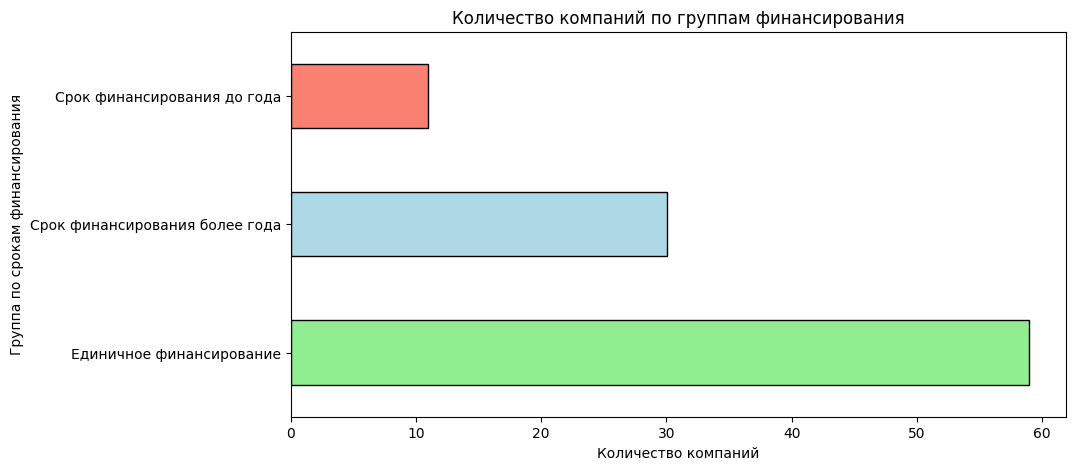

In [42]:
# построим линейчатую диаграмму
colors = count_company.index.map(color_map)

count_company.plot(kind="barh", figsize=(10, 5), color=colors, edgecolor="black")

plt.title("Количество компаний по группам финансирования")
plt.xlabel("Количество компаний")
plt.ylabel("Группа по срокам финансирования")

plt.show()

In [43]:
# сгруппируем данные по объему инвестиций для каждой группы
investment_volume = df.groupby("financing_time")["funding_total_usd"].sum()
investment_volume

financing_time
Единичное финансирование          1.993044e+11
Срок финансирования более года    4.027433e+11
Срок финансирования до года       4.888598e+10
Name: funding_total_usd, dtype: float64

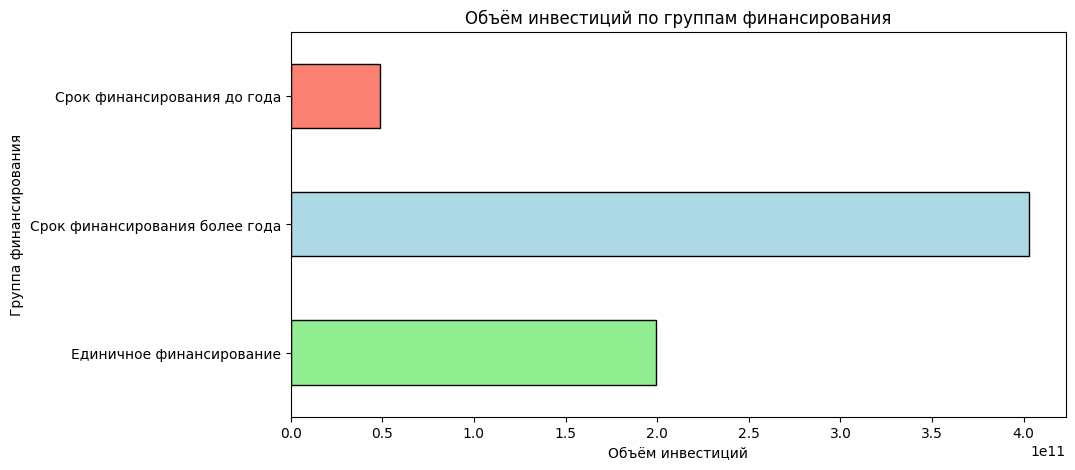

In [44]:
# построим линейчатую диаграмму
colors = investment_volume.index.map(color_map)

investment_volume.plot(
    kind="barh",
    figsize=(10, 5),
    color=colors,
    edgecolor="black",
    title="Объём инвестиций по группам финансирования",
)

plt.xlabel("Объём инвестиций")
plt.ylabel("Группа финансирования")
plt.show()

**Выводы:**

Большинство компаний (59%) финансируются только один раз, компании с длительным финансированием (> 1 года) составляют около 30%, компании с инвестициями до года встречаются реже всего — 11%.
Рынок по количеству компаний сильно смещён в сторону стартапов с единичным привлечением средств, что говорит о высокой “смертности” или раннем завершении финансирования.

По объему финансирования: 
- Наибольший объём капитала приходится на компании с финансированием более 1 года — около 403 млрд.долларов
- Компании с единичным финансированием привлекают значительно меньше средств (~199 млрд долларов), несмотря на их численное доминирование.
- Минимальный объём инвестиций наблюдается у компаний с коротким циклом (до года) — около 49 млрд долларов.

Основной капитал сосредоточен в долгосрочных инвестиционных проектах, что указывает на приоритет инвесторов к зрелым и устойчивым компаниям.

По количеству доминируют однораундовые компании, по объему финансирования - долгосрочные проекты

Наблюдается дисбаланс:
много стартапов ≠ много денег, инвесторы неохотно готовы много вкладывать в новые проекты, либо большая часть проектов не выживает

###  <a id='bullet_6'></a> Выделение средних и нишевых сегментов рынка

Компании указывают свой сегмент рынка в столбце `market`. Рассчитайте, как часто в датасете встречается каждый из сегментов. Сегменты, к которым относится более 120 компаний, отнесите к массовым, сегменты, в которые входит от 35 до 120 включительно, отнесите к средним, а сегменты до 35 компаний отнесите к нишевым. Рассчитайте, сколько сегментов попадает в каждую из категорий.

Постройте график распределения количества компаний в сегментах и отобразите на нём разделение на нишевые и средние сегменты.

In [45]:
# приведем данные в столбце к строчному виду  удалим пробелы
df["market"] = df["market"].str.strip().str.lower()

In [46]:
# посмотрим на расспределение компаний по сегментам
market_counts = df["market"].value_counts()
market_counts

market
software                 4812
biotechnology            3590
unknown                  2503
mobile                   2344
e-commerce               1866
                         ... 
employment                  1
real estate investors       1
business productivity       1
musicians                   1
gold                        1
Name: count, Length: 395, dtype: int64

In [47]:
# создадим новый спикок и разделим сегменты на массовые, средние и нишевые по количеству компаний
market_type = []

for count in market_counts:
    if count > 120:
        market_type.append("массовый")
    elif 35 <= count <= 120:
        market_type.append("средний")
    else:
        market_type.append("нишевый")

In [48]:
# создадим новый датафрейм, где сгруппируем сегменты по количеству компаний и наименованию сегмента
market_df = market_counts.reset_index()
market_df.columns = ["market", "companies"]
market_df["market_type"] = market_type
market_df

,market,companies,market_type
0,software,4812,массовый
1,biotechnology,3590,массовый
2,unknown,2503,массовый
3,mobile,2344,массовый
4,e-commerce,1866,массовый
...,...,...,...
390,employment,1,нишевый
391,real estate investors,1,нишевый
392,business productivity,1,нишевый
393,musicians,1,нишевый


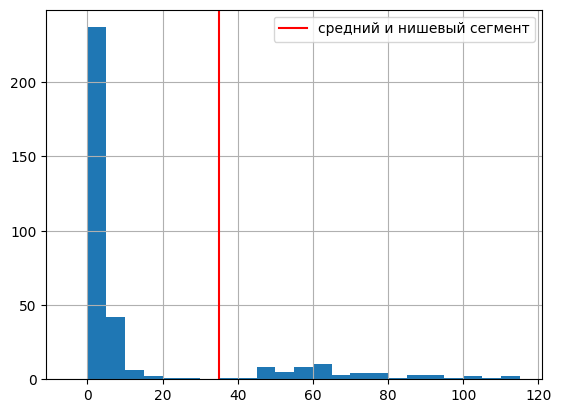

In [49]:
# график распределения количества компаний на нишевые и средние сегменты.
market_counts.hist(bins=range(-5, 120, 5))

plt.axvline(35, color="red", label="средний и нишевый сегмент")
plt.legend()

Оставьте в столбце `market` только массовые сегменты. Для остальных сегментов замените значения на заглушки — `niche` для нишевых и `mid` для средних.

Дальнейшие исследования выполняйте с учётом этой замены. Индивидуальные сегменты внутри средней и нишевой групп рассматривать не нужно — они объединяются в два общих сегмента.


In [50]:
# Оставляем в столбце market только массовые сегменты. Для остальных сегментов заглушки — niche для нишевых и mid для средних.
def market_group(x):
    if market_counts[x] > 120:
        return x
    elif market_counts[x] >= 35:
        return "mid"
    else:
        return "niche"


df["market"] = df["market"].apply(market_group)

In [51]:
df.head()

,name,homepage_url,category_list,market,funding_total_usd,status,country_code,state_code,region,city,funding_rounds,participants,founded_at,founded_month,founded_quarter,founded_year,first_funding_at,mid_funding_at,last_funding_at,seed,venture,equity_crowdfunding,undisclosed,convertible_note,debt_financing,angel,grant,private_equity,post_ipo_equity,post_ipo_debt,secondary_market,product_crowdfunding,round_a,round_b,round_c,round_d,round_e,round_f,round_g,round_h,financing_time
0,Harvard University,http://harvard.edu,|Education|,education,90000000.0,operating,USA,MA,Boston,Cambridge,1,<NA>,1636-09-08,unknown,unknown,1636,2014-01-06,2014-01-06,2014-01-06,0.0,0.0,0.0,0.0,0.0,0.0,0.0,90000000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Единичное финансирование
1,University of New Brunswick,http://www.unb.ca,unknown,unknown,2000000.0,operating,unknown,unknown,unknown,unknown,1,<NA>,1785-01-01,unknown,unknown,1785,2014-05-15,2014-05-15,2014-05-15,0.0,2000000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Единичное финансирование
2,DuPont,http://www.dupont.com,|Business Services|Agriculture|Automotive|Inve...,mid,9000000.0,operating,USA,DE,"Wilmington, Delaware",Wilmington,1,1,1802-07-19,unknown,unknown,1802,2009-07-02,2009-07-02,2009-07-02,0.0,9000000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Единичное финансирование
3,University of Michigan,http://www.umich.edu/,|Education|,education,7700000.0,operating,USA,MI,Detroit,Ann Arbor,3,0,1817-01-01,unknown,unknown,1817,2013-11-21,2013-11-21,2014-11-03,0.0,0.0,0.0,1600000.0,0.0,0.0,0.0,6100000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Срок финансирования до года
4,Case Western Reserve University,http://www.case.edu,|Education|,education,540000.0,operating,USA,OH,Cleveland,Cleveland,1,<NA>,1826-01-01,unknown,unknown,1826,2014-01-14,2014-01-14,2014-01-14,0.0,0.0,0.0,0.0,0.0,0.0,0.0,540000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Единичное финансирование


##  <a id='bullet_7'></a> Работа с выбросами и анализ

### <a id='bullet_8'></a> Анализируем и помечаем выбросы в каждом из сегментов

Заказчика интересует обычный для рассматриваемого периода размер средств, который предоставлялся компаниям.

По предобработанному столбцу `funding_total_usd` графическим образом оцените, какой размер общего финансирования для одной компании будет типичным, а какой — выбивающимся. Укажите интервал, в котором лежат типичные значения.

In [52]:
# посмотрим на разные данные столбца funding_total_usd
df["funding_total_usd"].describe()

count    4.090600e+04
mean     1.591291e+07
std      1.686808e+08
min      1.000000e+00
25%      3.500000e+05
50%      2.000000e+06
75%      1.000000e+07
max      3.007950e+10
Name: funding_total_usd, dtype: float64

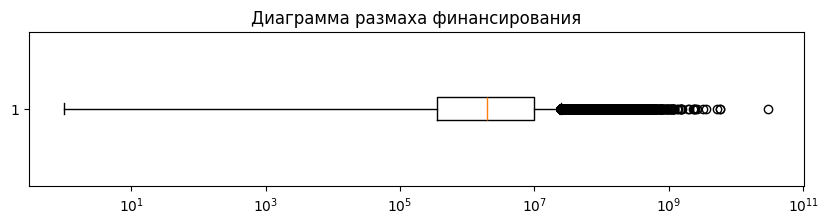

In [53]:
# построим график ящик с усами
plt.figure(figsize=(10, 2))

plt.boxplot(df["funding_total_usd"], vert=False)

plt.xscale("log")

plt.title("Диаграмма размаха финансирования")

plt.show()

**- 25%: 350 тыс. дол.**  
**- Медиана: 2 млн дол.**  
**- 75%: 10 млн дол.**  
**- Максимум: 30,08 млрд дол.**  
**Типичными можно считать значения от 350 тыс. до 10 млн долларов, так как именно в этом диапазоне находятся компании между 1 и 3 квартилем.**  
**При этом распределение сильно смещено вправо:**  
**медиана составляет всего 2 млн долларов;
среднее значение (15,9 млн долларов) значительно выше медианы из-за небольшого числа компаний с очень крупными объёмами финансирования;
максимальное значение (30 млрд долларов) существенно превышает 3-ий квартиль (10 млн долларов), поэтому такие суммы можно считать выбросами.**

Определите компании с аномальным объёмом общего финансирования — используйте метод IQR отдельно по каждому сегменту. Напомним, что все нишевые сегменты должны быть объединены в одну группу, а средние — в другую.

Определите сегменты рынка с наибольшей долей компаний, получивших аномальное финансирование, и выведите топ таких сегментов.

In [54]:
# посчитаем аномальное значение для каждого сегмента через метод IQR
q1 = df["funding_total_usd"].quantile(0.25)
q3 = df["funding_total_usd"].quantile(0.75)

iqr = q3 - q1

lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr
upper_bound

np.float64(24475000.0)

In [55]:
markets = df["market"].unique()

In [56]:
# создадим столбец, где укажем аномальное ли было финансирование (True) или нет (False)
df["anomaly"] = False

for market_types in markets:
    filntered = df[df["market"] == market_types]
    df.loc[df["funding_total_usd"] > 24475000, "anomaly"] = True

In [57]:
# посчитаем долю в каждом сегменте
outlier_share = (
    df.groupby("market")["anomaly"].mean().sort_values(ascending=False) * 100
).round(2)
outlier_share.head(10)

market
semiconductors         32.23
clean technology       27.63
health care            27.00
web hosting            26.18
technology             24.79
biotechnology          23.06
security               17.11
cloud computing        16.45
enterprise software    16.08
finance                15.34
Name: anomaly, dtype: float64

**Наибольшая доля компаний с аномальным объёмом финансирования наблюдается в сегменте Semiconductors — около 32,2% компаний получили объём инвестиций, который выходит за границы, определённые методом IQR. Также высокой долей аномалий отличаются сегменты Clean Technology (27,6%), Health Care (27,0%), Web Hosting (26,2%) и Technology (24,8%). Это говорит о том, что в этих сегментах чаще встречаются компании с необычно высокими объёмами финансирования**

###  <a id='bullet_9'></a>  Определяем границы рассматриваемого периода, отбрасываем аномалии

Проверьте по датасету, можно ли считать, что вам предоставили полные данные за 2014 год. Затем исключите из датасета компании, которые вы ранее посчитали получившими аномальное финансирование.

Когда исключите аномальные записи, на основе столбцов `mid_funding_at` и `funding_rounds` оставьте в датасете данные только об определённых компаниях. Они должны были получать финансирование в годы, когда было зафиксировано 50 или более раундов финансирования.

In [58]:
# проверим все ли данные есть за 2014 год
df["first_funding_at"].max()

Timestamp('2014-12-31 00:00:00')

In [59]:
df["last_funding_at"].max()

Timestamp('2014-12-31 00:00:00')

**Данные заканчиваются последней датой 2014 года (2014-12-31), следовательно ожно считать, что данные за 2014 год полные**

In [60]:
# исключаем данные с аномальным финансированием
df = df[df["anomaly"] == False]

In [61]:
df.shape[0]

35674

In [62]:
# оставляем года, шде было больше 50 раундов финансирования
df["mid_year"] = df["mid_funding_at"].dt.year

years = df["mid_year"].value_counts()

years = years[years >= 50].index

df = df[(df["mid_year"].isin(years))]

In [63]:
df["mid_year"].value_counts()

mid_year
2013    7845
2014    6210
2012    5554
2011    4294
2010    3414
2009    2559
2008    1929
2007    1581
2006    1173
2005     702
2004     103
2000      71
2003      65
2002      51
Name: count, dtype: int64

**После исключения компаний с аномальным объёмом финансирования было установлено, что условию о наличии не менее 50 раундов финансирования соответствуют годы с 2000 по 2014 (за исключением 2001 года). Более ранние годы, а также 2001 год, представлены небольшим числом наблюдений (менее 50), поэтому компании с датами среднего раунда финансирования в эти годы были исключены из дальнейшего анализа. Это позволяет проводить исследование на основе периодов, для которых объём данных является достаточным и результаты будут более надёжными**

###  <a id='bullet_10'></a> Анализ типов финансирования по объёму и популярности

Постройте график, который покажет, какие типы финансирования в сумме привлекли больше всего денег. Ориентируйтесь на значения в столбцах `seed`, `venture`, `equity_crowdfunding`, `undisclosed`, `convertible_note`, `debt_financing`, `angel`, `grant`, `private_equity`, `post_ipo_equity`, `post_ipo_debt`, `secondary_market` и `product_crowdfunding`.

Также постройте график, который покажет популярность разных типов финансирования — какие типы финансирования чаще всего используются компаниями, то есть встречаются в датасете наибольшее количество раз.

Сравните графики и выделите часто используемые типы финансирования, которые при этом характеризуются небольшими объёмами, и наоборот — те, что встречаются редко, но при этом характеризуются значительным объёмом предоставленных сумм.

In [64]:
# создадим список и посчитаем объём предоставленных сумм в год по каждому виду финансирования
funding_types = [
    "seed",
    "venture",
    "equity_crowdfunding",
    "undisclosed",
    "convertible_note",
    "debt_financing",
    "angel",
    "grant",
    "private_equity",
    "post_ipo_equity",
    "post_ipo_debt",
    "secondary_market",
    "product_crowdfunding",
]

funding_sum = df[funding_types].sum().sort_values(ascending=False)
funding_sum

venture                 1.080934e+11
seed                    9.636956e+09
debt_financing          5.878786e+09
private_equity          3.205556e+09
angel                   2.642941e+09
undisclosed             2.208045e+09
grant                   1.900136e+09
post_ipo_equity         1.097385e+09
convertible_note        5.004811e+08
equity_crowdfunding     2.787173e+08
product_crowdfunding    2.129356e+08
post_ipo_debt           1.698091e+08
secondary_market        4.528580e+07
dtype: float64

In [65]:
# посчитаем количество каждого вида финансирования
funding_count = (df[funding_types] != 0).sum().sort_values(ascending=False)
funding_count

venture                 18764
seed                    13483
debt_financing           3073
angel                    2991
grant                    1000
undisclosed               827
private_equity            588
equity_crowdfunding       520
convertible_note          509
product_crowdfunding      208
post_ipo_equity           142
post_ipo_debt              24
secondary_market            7
dtype: int64

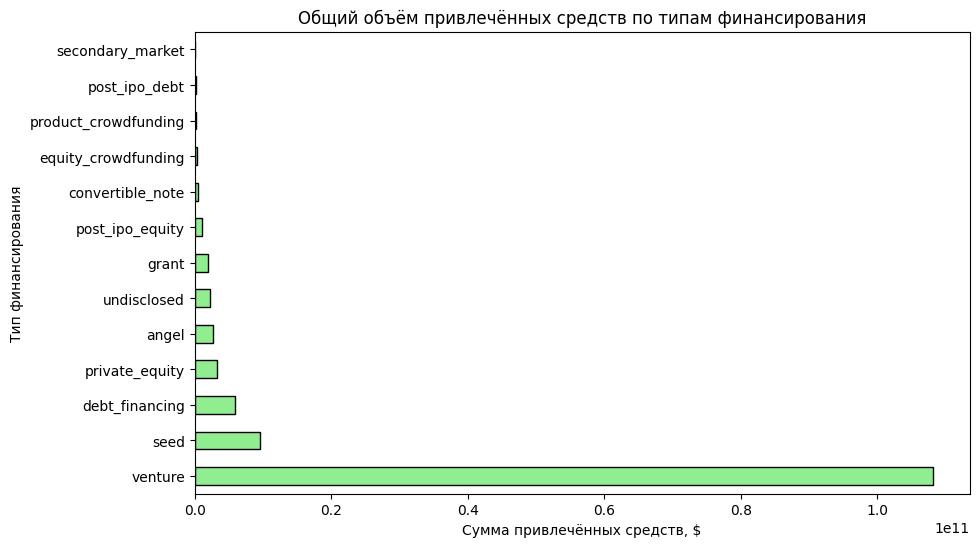

In [66]:
# построим графики по полученным данным
plt.figure(figsize=(10, 6))

funding_sum.plot(kind="barh", color="lightgreen", edgecolor="black")

plt.title("Общий объём привлечённых средств по типам финансирования")
plt.xlabel("Сумма привлечённых средств, $")
plt.ylabel("Тип финансирования")

plt.show()

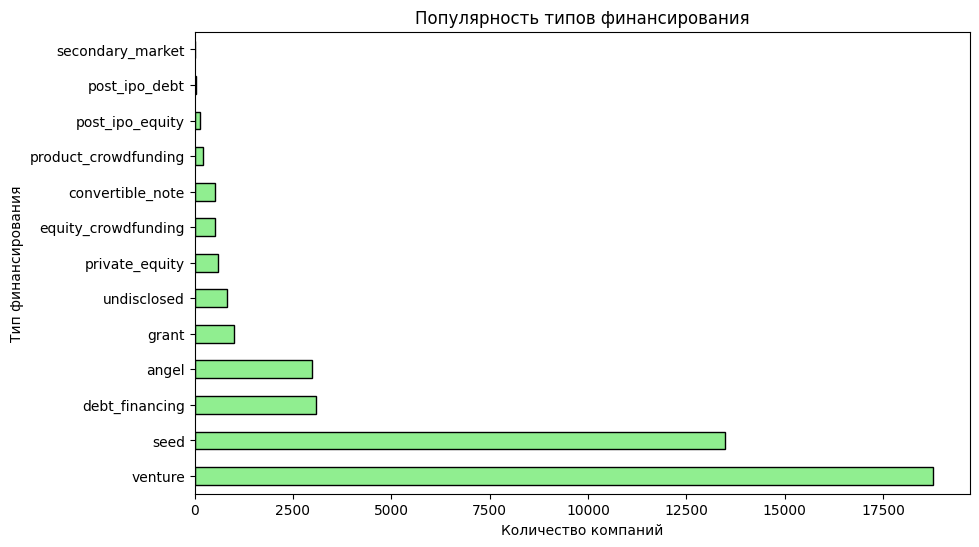

In [67]:
funding_count.plot(kind="barh", figsize=(10, 6), color="lightgreen", edgecolor="black")

plt.title("Популярность типов финансирования")
plt.xlabel("Количество компаний")
plt.ylabel("Тип финансирования")

plt.show()

**Наиболее часто компании используют venture и seed-финансирование. При этом venture одновременно является лидером и по количеству сделок, и по общему объёму привлечённых средств. Seed также используется очень часто, однако объём привлечённого капитала значительно уступает венчурному финансированию, что связано с небольшими суммами инвестиций на ранних стадиях развития компаний.  
  Напротив, private equity встречается сравнительно редко, но входит в число лидеров по общему объёму инвестиций. Это говорит о том, что сделки такого типа обычно сопровождаются крупными вложениями. Аналогичная ситуация наблюдается у post IPO equity — этот тип финансирования используется редко, однако объём привлекаемых средств остаётся высоким. В свою очередь, grant и angel финансирование применяются достаточно часто, но их общий объём значительно ниже, поскольку такие инвестиции обычно имеют меньший размер.**

Постройте график суммарных объёмов возвратов от разных типов финансирования за весь период на основе дополнительного датасета.

In [68]:
# Строим график суммарных объёмов возвратов от разных типов финансирования за весь период на основе дополнительного датасета
return_types = [
    "seed",
    "venture",
    "equity_crowdfunding",
    "undisclosed",
    "convertible_note",
    "debt_financing",
    "angel",
    "grant",
    "private_equity",
    "post_ipo_equity",
    "post_ipo_debt",
    "secondary_market",
    "product_crowdfunding",
]

returns_sum = df_1[return_types].sum().sort_values(ascending=False)

returns_sum

venture                 40578.62
debt_financing           4734.85
private_equity           3587.33
seed                     2382.24
angel                    1509.23
post_ipo_equity          1104.96
undisclosed               730.88
post_ipo_debt              91.03
convertible_note           34.79
secondary_market            5.20
equity_crowdfunding         3.83
product_crowdfunding        1.86
grant                       0.00
dtype: float64

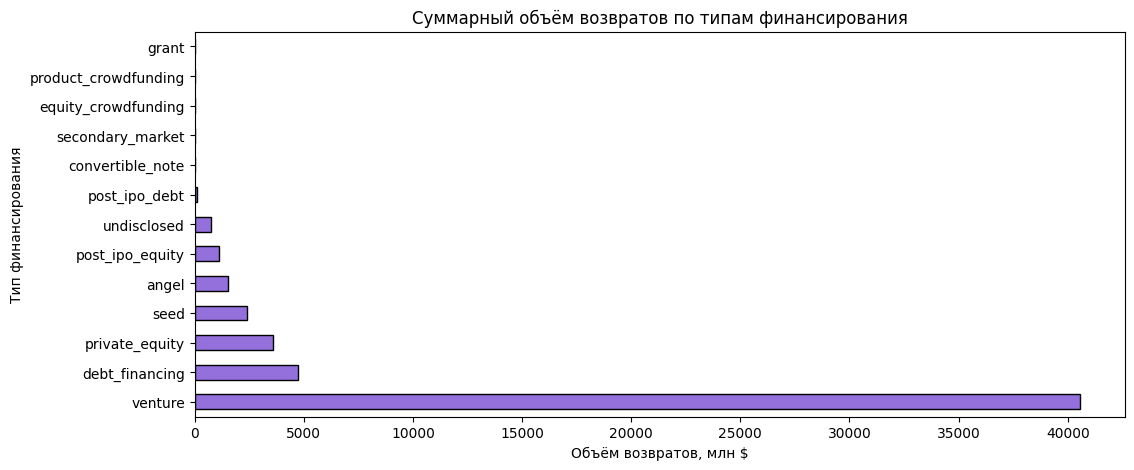

In [69]:
returns_sum.plot(kind="barh", figsize=(12, 5), color="mediumpurple", edgecolor="black")

plt.title("Суммарный объём возвратов по типам финансирования")
plt.xlabel("Объём возвратов, млн $")
plt.ylabel("Тип финансирования")

plt.show()

**Вывод: Наибольший объём возвратов инвестиций приходится на venture-финансирование — более 40,6 млрд долларов, что значительно превышает показатели остальных типов. Существенные объёмы возвратов также наблюдаются у debt financing (4,7 млрд долларов), private equity (3,6 млрд долларов) и seed (2,4 млрд долларов). В то же время grant, product crowdfunding, equity crowdfunding и secondary market практически не обеспечивают возврата средств, что связано со спецификой этих источников финансирования. В частности, гранты не предполагают возврат инвестиций, поэтому их суммарный объём возвратов равен нулю.  
Можно также отметить связь с предыдущими результатами:  
Сравнение объёмов финансирования и возвратов показывает, что venture-финансирование лидирует по обоим показателям: через него привлекается наибольший объём инвестиций и обеспечивается наибольший объём возвратов. Private equity, несмотря на сравнительно небольшое количество сделок, также демонстрирует высокие суммы возвратов, что свидетельствует о крупном размере таких инвестиций.**

##  <a id='bullet_11'></a>  Анализ динамики

###  <a id='bullet_12'></a> Динамика предоставления финансирования по годам

Используя столбцы `funding_total_usd` и `funding_rounds`, рассчитайте для каждой компании средний объём одного раунда финансирования.

На основе получившейся таблицы постройте графики, отражающие:
* динамику типичного размера средств, которые стартапы получали в рамках одного раунда финансирования;

* динамику общего количества раундов за каждый год, то есть насколько активно происходили инвестиции на рынке (чем больше раундов, тем выше активность).

Когда будете строить графики в этом задании и следующих, используйте данные только по тем компаниям, которые остались в датасете после предыдущих фильтраций.

На основе полученных данных ответьте на вопросы:
* В каком году типичный размер средств, собранных в рамках одного раунда, был максимальным?

* Какая тенденция наблюдалась в 2014 году по количеству раундов и средств, выделяемых в рамках каждого раунда?

In [70]:
# средний объём одного раунда финансирования
df["avg_round_funding"] = df["funding_total_usd"] / df["funding_rounds"]
df["avg_round_funding"]

1             2000000.0
2             9000000.0
3        2566666.666667
4              540000.0
5            19000000.0
              ...      
40900         8100000.0
40901         1500000.0
40902         9000000.0
40903          250000.0
40905           11500.0
Name: avg_round_funding, Length: 35551, dtype: Float64

In [71]:
# составим таблицу, где укажим типичный размер средств в рамках одного раунда финансирования и суммарное количество раундов в этом году
funding_year = (
    df.groupby(df["mid_funding_at"].dt.year).agg(
        typical_round=("avg_round_funding", "median"),
        total_rounds=("funding_rounds", "sum"),
    )
).round(2)

funding_year

,typical_round,total_rounds
mid_funding_at,,
2000,3110000.0,130
2002,3616666.67,99
2003,1510000.0,125
2004,3375000.0,183
2005,4500000.0,949
2006,3760000.0,1823
2007,2786666.67,2768
2008,2000000.0,3466
2009,1400000.0,4335


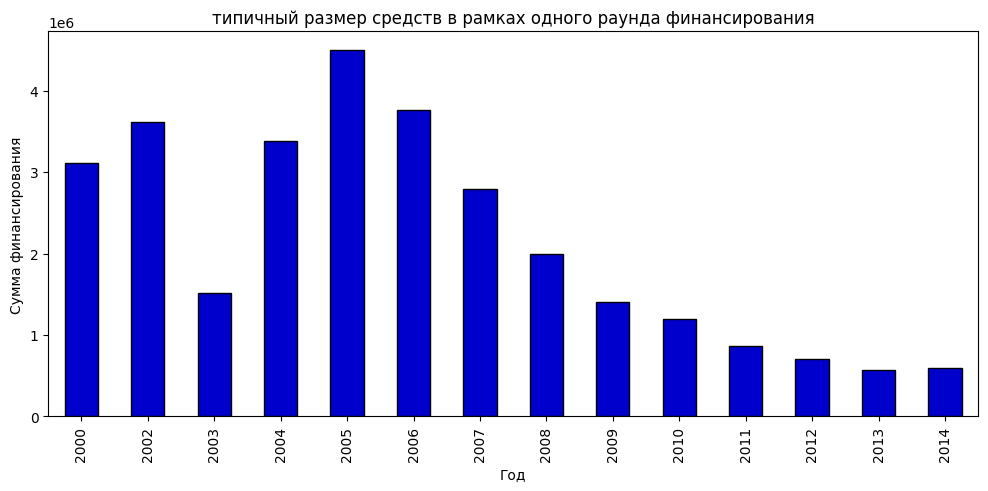

In [72]:
funding_year["typical_round"].plot(
    kind="bar", figsize=(12, 5), color="mediumblue", edgecolor="black"
)

plt.title("типичный размер средств в рамках одного раунда финансирования")
plt.xlabel("Год")
plt.ylabel("Сумма финансирования")

plt.show()

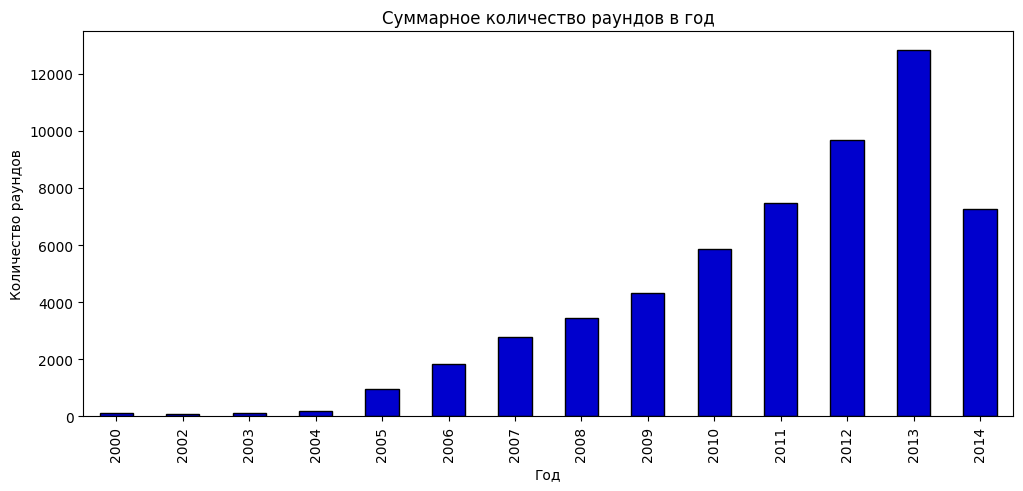

In [73]:
funding_year["total_rounds"].plot(
    kind="bar", figsize=(12, 5), color="mediumblue", edgecolor="black"
)

plt.title("Суммарное количество раундов в год")
plt.xlabel("Год")
plt.ylabel("Количество раундов")

plt.show()

**Максимальный типичный размер одного раунда финансирования был зафиксирован в 2005 году и составил 4,5 млн долларов. В дальнейшем этот показатель постепенно снижался, что свидетельствует об уменьшении типичного объёма инвестиций в одном раунде. В 2014 году количество раундов финансирования заметно сократилось по сравнению с предыдущим годом, однако типичный размер одного раунда немного увеличился. Это может указывать на снижение инвестиционной активности при небольшом росте среднего объёма финансирования одной сделки**

###  <a id='bullet_13'></a> Динамика размера общего финансирования по массовым сегментам рынка для растущих в 2014 году сегментов

Составьте сводную таблицу, в которой указывается суммарный размер общего финансирования `funding_total_usd` по годам и сегментам рынка. Отберите из неё только те сегменты, которые показывали рост размера суммарного финансирования в 2014 году по сравнению с 2013.

На графике отразите, как менялся суммарный размер общего финансирования в каждом из отобранных сегментов по годам, за которые у вас достаточно данных. Рассматривайте только массовые сегменты, а средние и нишевые исключите.

На основе графика сделайте вывод о том, какие сегменты показывают наиболее быстрый и уверенный рост.

In [74]:
# исключаем средние и нишевые сегменты
mass_df = df[~df["market"].isin(["mid", "niche", "unknown"])]

In [75]:
# создаем сводную таблицу в которой указывается суммарный размер общего финансирования funding_total_usd по годам и сегментам рынка
funding_pivot = mass_df.pivot_table(
    values="funding_total_usd",
    index="market",
    columns=mass_df["mid_funding_at"].dt.year,
    aggfunc="sum",
)

funding_pivot

mid_funding_at,2000,2002,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014
market,,,,,,,,,,,,,,
advertising,14470000.0,24500000.0,10500000.0,6000000.0,1.016960e+08,2.227278e+08,5.037043e+08,5.448970e+08,5.132914e+08,6.046179e+08,3.318247e+08,4.956370e+08,5.249151e+08,1.827923e+08
analytics,14822803.0,7500000.0,3840000.0,3000000.0,7.901404e+07,1.397013e+08,4.882900e+07,1.563778e+08,1.409493e+08,2.292399e+08,3.933334e+08,5.138244e+08,6.228214e+08,1.514616e+08
apps,NaN,NaN,NaN,NaN,NaN,1.310600e+06,2.025000e+07,2.140000e+07,5.275575e+07,6.820918e+07,2.437407e+07,8.043279e+07,7.911414e+07,1.472519e+08
automotive,NaN,NaN,4530000.0,NaN,2.250000e+07,1.266000e+07,3.771260e+07,5.947864e+07,2.080031e+07,1.769692e+07,7.645216e+07,3.555768e+07,1.175725e+08,6.903416e+07
big data,NaN,NaN,NaN,NaN,NaN,NaN,7.780000e+06,2.452515e+06,5.973750e+05,5.698330e+07,6.036916e+07,1.494583e+08,1.149989e+08,1.028326e+08
biotechnology,NaN,NaN,42031178.0,45119644.0,2.907636e+08,4.505244e+08,7.760954e+08,7.388624e+08,1.897263e+09,2.160768e+09,2.263340e+09,2.391403e+09,3.182038e+09,1.490952e+09
clean technology,NaN,NaN,2175000.0,19427954.0,1.942000e+07,2.587000e+07,2.285450e+08,1.203162e+09,6.720922e+08,6.002767e+08,6.668917e+08,5.656042e+08,6.440075e+08,3.252868e+08
cloud computing,11500000.0,NaN,NaN,NaN,NaN,9.951809e+06,2.035434e+07,4.437500e+07,5.222372e+07,8.525538e+06,7.315140e+07,7.442158e+07,8.484678e+07,7.344086e+07
consulting,4500000.0,NaN,NaN,NaN,6.486200e+07,6.793019e+07,1.038463e+08,1.906108e+07,1.222677e+08,1.179149e+08,1.675321e+08,1.069327e+08,1.535040e+08,8.632213e+07


In [76]:
# берем только те сегменты, где размер суммарного финансирования в 2014 году > чем в 2013
growth_segments = funding_pivot[2014] > funding_pivot[2013]

funding_growth = funding_pivot[growth_segments]
funding_growth

mid_funding_at,2000,2002,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014
market,,,,,,,,,,,,,,
apps,NaN,NaN,NaN,NaN,NaN,1310600.0,20250000.0,21400000.0,52755748.0,68209179.0,24374071.0,80432791.0,79114136.0,147251866.0
internet,10000000.0,1100000.0,NaN,10500000.0,1775000.0,21405000.0,4495379.0,42802962.0,38195773.0,57657500.0,56859032.0,56869212.0,83132096.0,130655982.0
medical,24000000.0,NaN,NaN,NaN,11090000.0,20250000.0,2100000.0,28812744.0,11566200.0,25590338.0,28540962.0,44039600.0,64469424.0,175236064.0
nonprofits,6500000.0,NaN,NaN,NaN,17051520.0,12880000.0,200000.0,23110739.0,18366000.0,34954984.0,115910233.0,24039316.0,71155457.0,72341299.0
real estate,2500000.0,5275000.0,6292200.0,NaN,250000.0,22080000.0,56220000.0,46613100.0,77390213.0,54444608.0,55415128.0,77320857.0,172350754.0,193467364.0
saas,NaN,2000000.0,NaN,NaN,5240000.0,4791121.0,74252585.0,27226900.0,13536585.0,46859390.0,149882660.0,72499912.0,90376613.0,152807752.0
sports,NaN,200000.0,NaN,NaN,1882200.0,7000000.0,42401580.0,28429977.0,57680625.0,74124319.0,33184258.0,115388940.0,36208524.0,58456511.0
startups,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5010387.0,460700.0,16904366.0,40804403.0,26843782.0,63032467.0,75501837.0
technology,NaN,11000000.0,NaN,1750000.0,20728425.0,22791000.0,16990209.0,53366236.0,4978850.0,134922280.0,83522700.0,92709865.0,82461469.0,172018937.0


In [77]:
# исключим года с пропусками, чтобы данные были полными
funding_growth.isna().sum()

mid_funding_at
2000    6
2002    5
2003    8
2004    7
2005    2
2006    1
2007    1
2008    0
2009    0
2010    0
2011    0
2012    0
2013    0
2014    0
dtype: int64

In [78]:
funding_growth = funding_growth.dropna(axis=1)
funding_growth

mid_funding_at,2008,2009,2010,2011,2012,2013,2014
market,,,,,,,
apps,21400000.0,52755748.0,68209179.0,24374071.0,80432791.0,79114136.0,147251866.0
internet,42802962.0,38195773.0,57657500.0,56859032.0,56869212.0,83132096.0,130655982.0
medical,28812744.0,11566200.0,25590338.0,28540962.0,44039600.0,64469424.0,175236064.0
nonprofits,23110739.0,18366000.0,34954984.0,115910233.0,24039316.0,71155457.0,72341299.0
real estate,46613100.0,77390213.0,54444608.0,55415128.0,77320857.0,172350754.0,193467364.0
saas,27226900.0,13536585.0,46859390.0,149882660.0,72499912.0,90376613.0,152807752.0
sports,28429977.0,57680625.0,74124319.0,33184258.0,115388940.0,36208524.0,58456511.0
startups,5010387.0,460700.0,16904366.0,40804403.0,26843782.0,63032467.0,75501837.0
technology,53366236.0,4978850.0,134922280.0,83522700.0,92709865.0,82461469.0,172018937.0


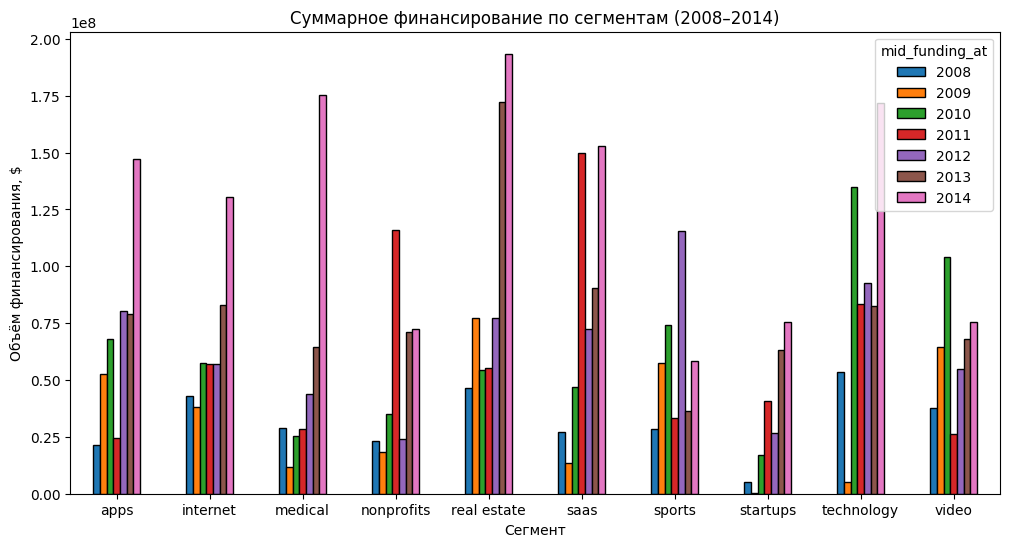

In [79]:
funding_growth.plot(kind="bar", figsize=(12, 6), edgecolor="black")

plt.title("Суммарное финансирование по сегментам (2008–2014)")
plt.xlabel("Сегмент")
plt.ylabel("Объём финансирования, $")
plt.xticks(rotation=0)

plt.show()

**Наиболее уверенный рост показывают:  
Real Estate — один из лидеров по объёму финансирования. После небольшого снижения в 2010 году финансирование быстро растёт и достигает 193 млн долларов в 2014 году.  
Internet — после небольшого снижения в 2009 году финансирование практически непрерывно увеличивается и достигает около 131 млн долларов в 2014 году.  
Apps — несмотря на спад в 2011 году, после него наблюдается устойчивый рост, а к 2014 году объём финансирования увеличивается до 147 млн долларов.  
Medical — после 2009 года наблюдается последовательный рост, особенно заметный в последние годы периода.  
Наиболее быстрый рост демонстрируют:  
Менее стабильную динамику имеют:**  
**- Sports;**  
**- Video;**  
**- Nonprofits;**  
**- Startups.  
Для них характерны значительные колебания объёмов финансирования между годами без выраженного устойчивого восходящего тренда**

###  <a id='bullet_14'></a> Годовая динамика доли возвращённых средств по типам финансирования

Заказчик хочет знать, какая часть вложенных или выданных денег со временем возвращается обратно инвесторам или финансистам. Ваша цель — для каждого года и каждого вида финансирования рассчитать нормированные значения возврата средств: то есть какую долю возвращённые средства составляют от предоставленных. При этом слишком большие аномальные значения, то есть неадекватные выбросы, нужно заменить на пропуски.

Совет: когда будете делить сумму возвращённых средств на суммарный объём привлечённого финансирования по конкретному году, добавьте к знаменателю небольшое число, например `1e-60`. Это поможет избежать деления на ноль.

In [80]:
# переведем данные в один вид исчисления
df_1 = df_1 * 1e6
df_1

,seed,venture,equity_crowdfunding,undisclosed,convertible_note,debt_financing,angel,grant,private_equity,post_ipo_equity,post_ipo_debt,secondary_market,product_crowdfunding
year,,,,,,,,,,,,,
2000,16700000.0,5.540000e+07,0.0,78210000.0,0.0,8.660000e+06,6430000.0,0.0,0.0,940000.0,0.0,200000.0,0.0
2001,2880000.0,2.349000e+07,0.0,21500000.0,10000.0,4.490000e+06,1180000.0,0.0,0.0,460000.0,0.0,460000.0,0.0
2002,6590000.0,2.094200e+08,0.0,25770000.0,20000.0,3.420000e+06,3410000.0,0.0,1510000.0,340000.0,0.0,60000.0,0.0
2003,7740000.0,2.338600e+08,0.0,9400000.0,10000.0,1.090000e+06,3410000.0,0.0,1620000.0,2110000.0,0.0,80000.0,0.0
2004,9930000.0,5.559000e+08,0.0,33190000.0,10000.0,1.355000e+07,9180000.0,0.0,2190000.0,3380000.0,0.0,550000.0,0.0
2005,26600000.0,2.628920e+09,0.0,9510000.0,20000.0,3.509000e+07,31060000.0,0.0,2400000.0,3510000.0,0.0,50000.0,0.0
2006,61810000.0,3.100180e+09,190000.0,46740000.0,1780000.0,1.132100e+08,47750000.0,0.0,16670000.0,20580000.0,0.0,120000.0,0.0
2007,70410000.0,3.585370e+09,10000.0,55370000.0,3220000.0,1.256800e+08,164510000.0,0.0,88810000.0,24360000.0,0.0,570000.0,0.0
2008,89720000.0,2.717020e+09,30000.0,41020000.0,1710000.0,3.975400e+08,102830000.0,0.0,130380000.0,84280000.0,0.0,470000.0,0.0


In [81]:
# создадим датафрейм, где сгрупируем данные по объему средств по видам финансирования в год
df_year_sum = df.groupby(df["mid_year"])[funding_types].sum()
df_year_sum

,seed,venture,equity_crowdfunding,undisclosed,convertible_note,debt_financing,angel,grant,private_equity,post_ipo_equity,post_ipo_debt,secondary_market,product_crowdfunding
mid_year,,,,,,,,,,,,,
2000,1.675914e+07,2.907648e+08,0.0,178652640.0,0.0,7.000000e+06,26086333.0,293114.0,0.000000e+00,3467747.0,0.0,7718867.0,0.0
2002,9.465192e+06,2.995585e+08,0.0,42323731.0,0.0,1.430967e+07,3000000.0,0.0,1.644188e+07,300000.0,0.0,0.0,0.0
2003,1.093329e+07,3.418007e+08,0.0,10280000.0,0.0,1.050000e+06,9271850.0,16850717.0,0.000000e+00,0.0,0.0,0.0,0.0
2004,1.710473e+07,7.077851e+08,0.0,46692945.0,0.0,2.101662e+07,11013741.0,10363600.0,0.000000e+00,0.0,0.0,0.0,0.0
2005,4.092520e+07,4.427609e+09,0.0,27462243.0,0.0,6.370934e+07,62914621.0,6266481.0,5.000000e+06,4796022.0,0.0,0.0,0.0
2006,7.152683e+07,7.889979e+09,933057.0,42314656.0,11807857.0,1.155621e+08,72776153.0,1147500.0,3.006537e+07,0.0,0.0,0.0,0.0
2007,2.022455e+08,9.451288e+09,0.0,103182339.0,11134794.0,1.863964e+08,222152441.0,17693300.0,7.294033e+07,12000000.0,0.0,0.0,0.0
2008,3.111280e+08,1.041228e+10,0.0,116859228.0,15355861.0,2.741351e+08,256249613.0,22285347.0,4.654633e+07,0.0,0.0,0.0,1000000.0
2009,2.898034e+08,1.051759e+10,2049671.0,101205348.0,34108300.0,7.569596e+08,169589726.0,116760085.0,1.300408e+08,24482403.0,90750.0,19300000.0,303050.0


In [82]:
# рассчитаем долю возвратов
return_share = df_1 / df_year_sum.replace(0, None) * 100
return_share = return_share.drop(index=2001)
return_share

,seed,venture,equity_crowdfunding,undisclosed,convertible_note,debt_financing,angel,grant,private_equity,post_ipo_equity,post_ipo_debt,secondary_market,product_crowdfunding
year,,,,,,,,,,,,,
2000,99.647118,19.053204,NaN,43.777691,NaN,123.714286,24.648922,0.0,NaN,27.106937,NaN,2.591054,NaN
2002,69.623522,69.909559,NaN,60.887827,NaN,23.899921,113.666667,NaN,9.183866,113.333333,NaN,NaN,NaN
2003,70.792989,68.419985,NaN,91.439689,NaN,103.809524,36.777989,0.0,NaN,NaN,NaN,NaN,NaN
2004,58.054124,78.540788,NaN,71.081402,NaN,64.472775,83.350426,0.0,NaN,NaN,NaN,NaN,NaN
2005,64.996631,59.375610,NaN,34.629364,NaN,55.078268,49.368493,0.0,48.0,73.185653,NaN,NaN,NaN
2006,86.415124,39.292626,20.363172,110.458183,15.074708,97.964623,65.612152,0.0,55.445854,NaN,NaN,NaN,NaN
2007,34.814121,37.935252,NaN,53.662284,28.918362,67.426211,74.052754,0.0,121.75706,203.0,NaN,NaN,NaN
2008,28.837004,26.094382,NaN,35.102063,11.135813,145.016097,40.128841,0.0,280.108007,NaN,NaN,NaN,0.0
2009,55.282307,23.781960,8.781897,37.053378,6.596635,52.063543,57.320689,0.0,156.643196,313.531315,0.0,0.621762,6.599571


In [83]:
# приведем полученные данные к типу float64
return_share = return_share.apply(pd.to_numeric, errors="coerce")

In [84]:
# удалим аномальные значения
q1 = return_share.quantile(0.25)
q3 = return_share.quantile(0.75)

iqr = q3 - q1

upper_bound = q3 + 1.5 * iqr

return_share = return_share.mask(return_share > upper_bound)
return_share

,seed,venture,equity_crowdfunding,undisclosed,convertible_note,debt_financing,angel,grant,private_equity,post_ipo_equity,post_ipo_debt,secondary_market,product_crowdfunding
year,,,,,,,,,,,,,
2000,99.647118,19.053204,NaN,43.777691,NaN,123.714286,24.648922,0.0,NaN,27.106937,NaN,2.591054,NaN
2002,69.623522,69.909559,NaN,60.887827,NaN,23.899921,113.666667,NaN,9.183866,113.333333,NaN,NaN,NaN
2003,70.792989,68.419985,NaN,91.439689,NaN,103.809524,36.777989,0.0,NaN,NaN,NaN,NaN,NaN
2004,58.054124,78.540788,NaN,71.081402,NaN,64.472775,83.350426,0.0,NaN,NaN,NaN,NaN,NaN
2005,64.996631,59.375610,NaN,34.629364,NaN,55.078268,49.368493,0.0,48.000000,73.185653,NaN,NaN,NaN
2006,86.415124,39.292626,NaN,NaN,15.074708,97.964623,65.612152,0.0,55.445854,NaN,NaN,NaN,NaN
2007,34.814121,37.935252,NaN,53.662284,NaN,67.426211,74.052754,0.0,121.757060,203.000000,NaN,NaN,NaN
2008,28.837004,26.094382,NaN,35.102063,11.135813,145.016097,40.128841,0.0,280.108007,NaN,NaN,NaN,0.000000
2009,55.282307,23.781960,8.781897,37.053378,6.596635,52.063543,57.320689,0.0,156.643196,313.531315,0.000000,0.621762,6.599571


Постройте график, на котором отобразите нормированные значения возврата средств для типов финансирования `venture`, `debt_financing`, `private_equity`, `seed` и `angel`.

Сделайте вывод о том, в каких типах финансирования наблюдается наиболее устойчивый рост показателя.

In [85]:
selected = return_share[
    ["venture", "debt_financing", "private_equity", "seed", "angel"]
]

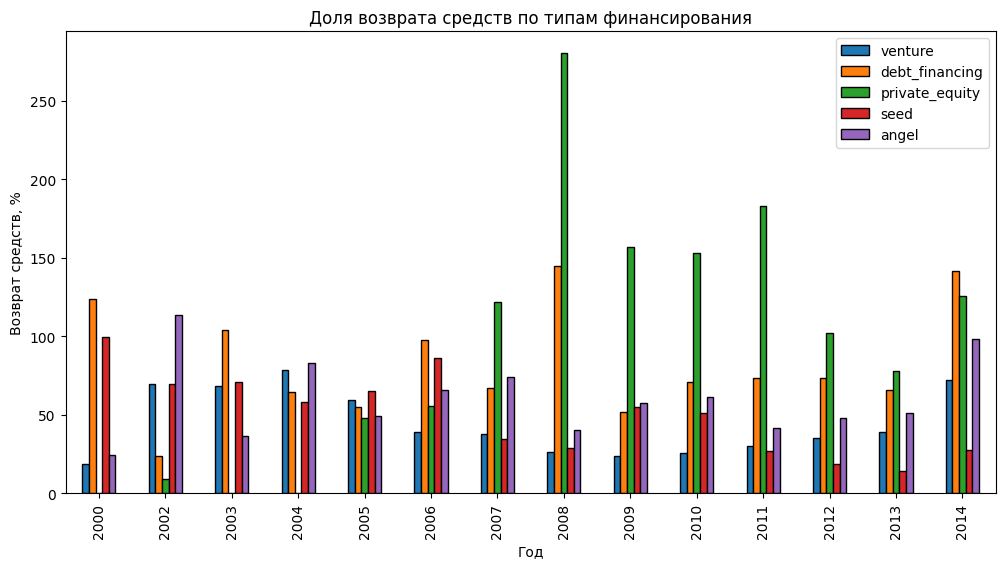

In [86]:
selected.plot(kind="bar", figsize=(12, 6), edgecolor="black")

plt.title("Доля возврата средств по типам финансирования")
plt.xlabel("Год")
plt.ylabel("Возврат средств, %")


plt.show()

**Наиболее устойчивый рост демонстрирует venture: после относительно низкого уровня в 2008–2010 годах доля возврата средств постепенно увеличивается и к 2014 году достигает около 73%. Это свидетельствует о стабильном повышении эффективности вложений этого типа.  
Для angel также наблюдается общий восходящий тренд, хотя динамика менее равномерна и сопровождается колебаниями.  
Debt financing характеризуется высокой волатильностью: показатель сильно меняется от года к году, достигая пиковых значений, поэтому устойчивого роста не наблюдается.  
Seed финансирование, наоборот, демонстрирует долгосрочное снижение показателя возврата по сравнению с началом периода, лишь с небольшим восстановлением в конце.  
Private equity отличается наиболее нестабильной динамикой: наблюдаются очень высокие значения в отдельные годы (например, 2008–2011), что говорит о сильной изменчивости показателя и не позволяет говорить об уверенном устойчивом росте.**


##  <a id='bullet_15'></a>  Итоговый вывод и рекомендации

Представьте, что на календаре 2015 год. Опираясь на результаты анализа, дайте рекомендацию заказчику:

* в какую отрасль стоит инвестировать;
* какой тип финансирования при этом будет наиболее уместным.

Подведите итоги проекта:
* опишите, какие шаги были выполнены;
* какие выводы удалось сделать;
* насколько выводы согласуются между собой или, наоборот, вызывают сомнения.



**Итоги проекта**

В ходе выполнения проекта были подготовлены и исследованы данные о финансировании стартапов. На первом этапе была проведена предобработка данных: обработаны пропуски, исправлены типы данных, удалены дубликаты и выделены необходимые признаки, включая год получения финансирования. Далее были рассчитаны основные показатели и построены визуализации, позволяющие оценить распределение компаний по сегментам рынка, динамику объёмов инвестиций и особенности различных типов финансирования.

В результате анализа было установлено, что наиболее многочисленными являются сегменты Apps, Internet, Technology и SaaS, тогда как такие направления, как Sports, Nonprofits и Startups, относятся к нишевым. При исследовании динамики медианного финансирования было выявлено, что наиболее быстрый и уверенный рост с 2008 по 2014 год демонстрировали сегменты Technology, Medical, SaaS и Real Estate. Это свидетельствует о высоком интересе инвесторов к данным направлениям.

Дополнительно была рассчитана доля возврата средств по каждому типу финансирования. Для этого объём возвращённых средств был нормирован относительно общего объёма привлечённого финансирования по каждому году. Аномально большие значения были заменены пропусками, что позволило исключить влияние выбросов на результаты анализа. Среди наиболее распространённых типов финансирования (venture, debt financing, private equity, seed и angel) наиболее устойчивую динамику показал venture. Несмотря на отдельные колебания, именно этот тип финансирования характеризуется стабильной долей возврата средств на протяжении рассматриваемого периода.

Рекомендация заказчику. Наиболее перспективными направлениями для инвестирования можно считать Technology, SaaS и Medical, поскольку они демонстрируют устойчивый рост объёмов финансирования и высокий интерес со стороны инвесторов. Наиболее подходящим типом финансирования является venture, так как он сочетает значительные объёмы инвестиций со сравнительно стабильной динамикой возврата средств.

Полученные результаты в целом согласуются между собой: сегменты, привлекавшие наибольшие объёмы инвестиций, одновременно демонстрировали положительную динамику развития, а венчурное финансирование оказалось наиболее устойчивым инструментом инвестирования. Однако при интерпретации результатов следует учитывать, что по некоторым типам финансирования количество наблюдений оказалось небольшим, поэтому выводы по ним менее надёжны. 


[к содержанию](#bullet_16)